# 05 · Evaluación final

**Universidad de Especialidades Espíritu Santo (UEES)** · Maestría en Inteligencia Artificial
**Proyecto Integrador en Inteligencia Artificial (MIAR0545)** · Proyecto final
**Autor:** Jairo Wladimir Jhayya Perlaza · **Docente:** Gladys María Villegas Rugel · **Fecha:** octubre de 2026

**Proyecto:** Análisis comparativo de modelos de aprendizaje automático y arquitecturas Transformer para la clasificación
de tráfico de red cifrado sobre el dataset CESNET-TLS-Year22.


Este notebook reúne la evaluación final del modelo: su desempeño en datos que nunca se usaron para decidir, las
métricas propias del dominio, el análisis de errores, la equidad entre categorías y su robustez frente a escenarios
críticos. Lee los resultados de `results/semana5/` y `results/comparativa/`.

## Configuración

Se cargan las librerías y se ubica la raíz del proyecto subiendo carpetas hasta encontrar `configs/`, así el notebook
funciona sin importar desde dónde se abra. También se definen dos funciones pequeñas para leer resultados y mostrar
figuras.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

# La raíz del proyecto es la primera carpeta, subiendo desde aquí, que contiene configs/
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").exists())
RES = RAIZ / "results"
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 60)


def leer_json(ruta):
    """Lee un archivo JSON de resultados."""
    return json.loads(Path(ruta).read_text(encoding="utf-8"))


def figura(ruta, ancho=900):
    """Muestra una figura guardada por los scripts del proyecto."""
    display(Image(filename=str(ruta), width=ancho))


print("Raíz del proyecto:", RAIZ.name, "· resultados disponibles:", RES.exists())

Raíz del proyecto: pf · resultados disponibles: True


## 1. Desempeño en la prueba final

Octubre de 2022 se reservó para medir el resultado final: 872 731 flujos que ningún modelo usó para entrenar ni para
elegir hiperparámetros. La tabla compara la versión 2 con la configuración optimizada.

In [2]:
final = pd.read_csv(RES / "semana5" / "cierre" / "evaluacion_final.csv").drop(columns=["peor_categoria"])
display(final)
cierre = leer_json(RES / "semana5" / "cierre" / "comparacion.json")
for nombre, clave in (("Versión 2", "ic_v2"), ("Optimizado", "ic_optimizado")):
    ic = cierre[clave]
    print(f"{nombre}: F1 macro {ic['valor']:.4f} · IC 95 % [{ic['ic95_bajo']:.4f}; {ic['ic95_alto']:.4f}]")

,modelo,accuracy,f1_macro,recall_macro,precision_macro,f1_peor_categoria,auc_ovr,auc_pr
0,xgboost_v2,0.9004,0.9032,0.9026,0.9048,0.8296,0.9962,0.9581
1,xgboost_optimizado,0.9083,0.9111,0.9047,0.9184,0.8404,0.9967,0.9616


Versión 2: F1 macro 0.9032 · IC 95 % [0.9021; 0.9044]
Optimizado: F1 macro 0.9111 · IC 95 % [0.9100; 0.9122]


Los intervalos de confianza son muy estrechos, de unas dos décimas de punto, porque octubre tiene casi 900 000 flujos. Y no se
superponen, lo que confirma que la diferencia entre ambas configuraciones es real.

## 2. Métricas del dominio

Para un clasificador de tráfico importan tres cosas además del promedio: cómo le va a la categoría más difícil, si su
confianza es fiable y cuánto tarda en responder. La calibración se ve en la figura: cuando el modelo dice estar seguro
en un 90 %, debería acertar el 90 % de las veces.

Error de calibración esperado: 0.019
Tiempo por flujo (versión 2): 0.1486 ms


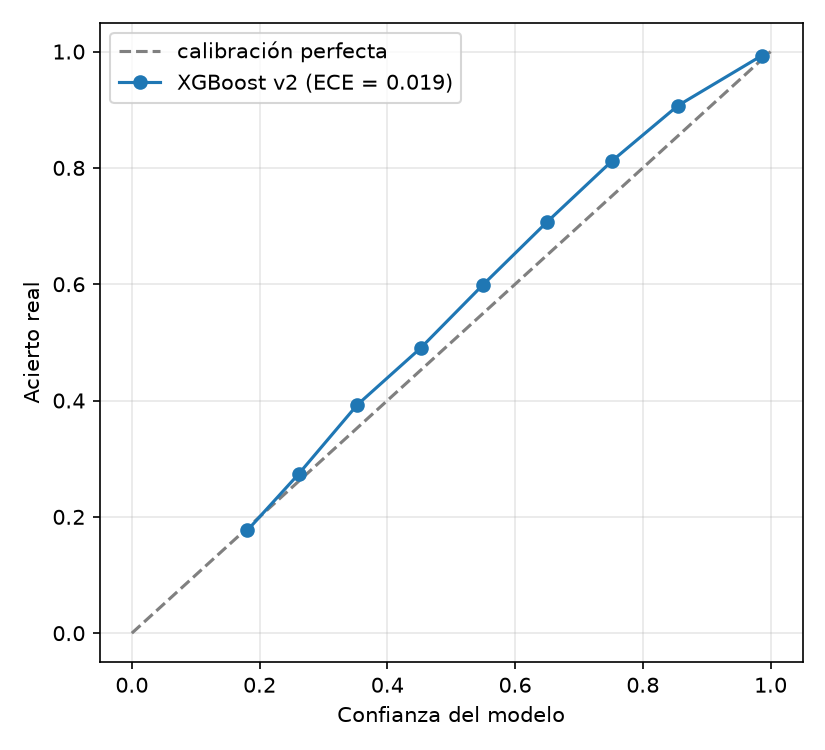

In [3]:
errores = leer_json(RES / "semana5" / "errores" / "resumen.json")
print(f"Error de calibración esperado: {errores['ece']:.3f}")
print("Tiempo por flujo (versión 2):", pd.read_csv(RES / "comparativa" / "tabla_comparativa.csv", index_col=0).loc["xgboost", "latencia_ms"], "ms")
figura(RES / "semana5" / "errores" / "calibracion.png", ancho=450)

El modelo está bien calibrado y es levemente conservador: acierta un poco más de lo que declara. Esa confianza permite
abstenerse de clasificar cuando el modelo duda.

## 3. Dónde se equivoca el modelo

Los errores no se reparten al azar. La primera tabla muestra los pares de categorías que más se confunden; la segunda,
cómo cambia el error según la longitud del flujo; la tercera, la diferencia entre secuencias ya vistas y nuevas.

In [4]:
display(pd.read_csv(RES / "semana5" / "errores" / "pares_confundidos.csv").head(8))
display(pd.read_csv(RES / "semana5" / "errores" / "error_por_longitud.csv"))
display(pd.read_csv(RES / "semana5" / "errores" / "repetidas_vs_nuevas.csv")[["secuencias", "flujos", "f1_macro"]])

,real,predicha,errores,fraccion_de_la_categoria,fraccion_de_todos_los_errores
0,Media,Social,2835,0.0404,0.0326
1,Social,Media,2522,0.0269,0.0290
2,Advertising,Media,2352,0.0271,0.0271
3,Media,Advertising,2072,0.0295,0.0238
4,Other APIs,Social,1861,0.0271,0.0214
5,Media,Other APIs,1843,0.0263,0.0212
6,Other services,Advertising,1615,0.0234,0.0186
7,Social,Other APIs,1598,0.0170,0.0184


,paquetes_del_flujo,flujos,tasa_error,f1_macro
0,"(4.999, 19.0]",216575,0.1093,0.8751
1,"(19.0, 22.0]",134995,0.0589,0.8870
2,"(22.0, 29.0]",190329,0.0816,0.9000
3,"(29.0, 58.0]",156889,0.1052,0.8778
4,"(58.0, 2135063.0]",173943,0.1335,0.8525


,secuencias,flujos,f1_macro
0,repetidas (vistas en septiembre),264700,0.9409
1,nuevas,608031,0.8853


Los errores se concentran en servicios que comparten infraestructura, como Media, Social y Advertising, y en los flujos
muy cortos o muy largos. En las secuencias que ya aparecieron en entrenamiento el modelo acierta 5,6 puntos más que en
las nuevas: es el efecto de la memorización.

## 4. Equidad entre categorías

El sistema no decide sobre personas, así que el grupo pertinente es el servicio. La tasa de acierto de cada categoría
se calculó con Fairlearn.

In [5]:
equidad = pd.read_csv(RES / "semana5" / "errores" / "equidad_por_categoria.csv")
print(f"Brecha entre la mejor y la peor categoría: {errores['diferencia_max']:.3f} · razón: {errores['razon_min']:.3f}")
pd.concat([equidad.head(4), equidad.tail(3)])

Brecha entre la mejor y la peor categoría: 0.160 · razón: 0.838


,categoria,tasa_acierto
0,Media,0.8279
1,Virtual assistant,0.8326
2,Other services,0.8463
3,Remote desktop,0.8557
20,Software updates,0.9627
21,Analytics & Telemetry,0.9628
22,Notifications,0.9875


Ninguna categoría baja de 0,80 de acierto, pero hay 16 puntos entre la mejor y la peor. Esa brecha se reporta siempre
junto al promedio.

## 5. Robustez frente a escenarios críticos

Cada escenario altera los datos de prueba de una forma controlada, se repite con 10 semillas y se compara con un umbral
fijado antes de ejecutar: una caída máxima de 5 puntos de F1 macro.

,escenario,nivel,f1_macro,f1_peor_categoria,accuracy,caida_f1,veredicto
0,Base,sin perturbar,0.9009,0.8220,0.8982,0.0000,OK
1,A · Ruido,σ=0.25,0.0780,0.0017,0.1213,0.8229,FALLA
2,A · Ruido,σ=0.5,0.0554,0.0000,0.0964,0.8455,FALLA
3,A · Ruido,σ=1.0,0.0439,0.0000,0.0817,0.8570,FALLA
4,A · Ruido,σ=1.5,0.0399,0.0000,0.0766,0.8610,FALLA
5,A' · Ruido realista,±5 % en tiempos y bytes,0.8735,0.7757,0.8716,0.0274,OK
6,A' · Ruido realista,±10 % en tiempos y bytes,0.8555,0.7631,0.8556,0.0454,OK
7,A' · Ruido realista,±20 % en tiempos y bytes,0.8233,0.7163,0.8268,0.0776,FALLA
8,B · Faltantes,10 %,0.8215,0.7286,0.8213,0.0794,FALLA
9,B · Faltantes,30 %,0.5585,0.3703,0.5763,0.3424,FALLA


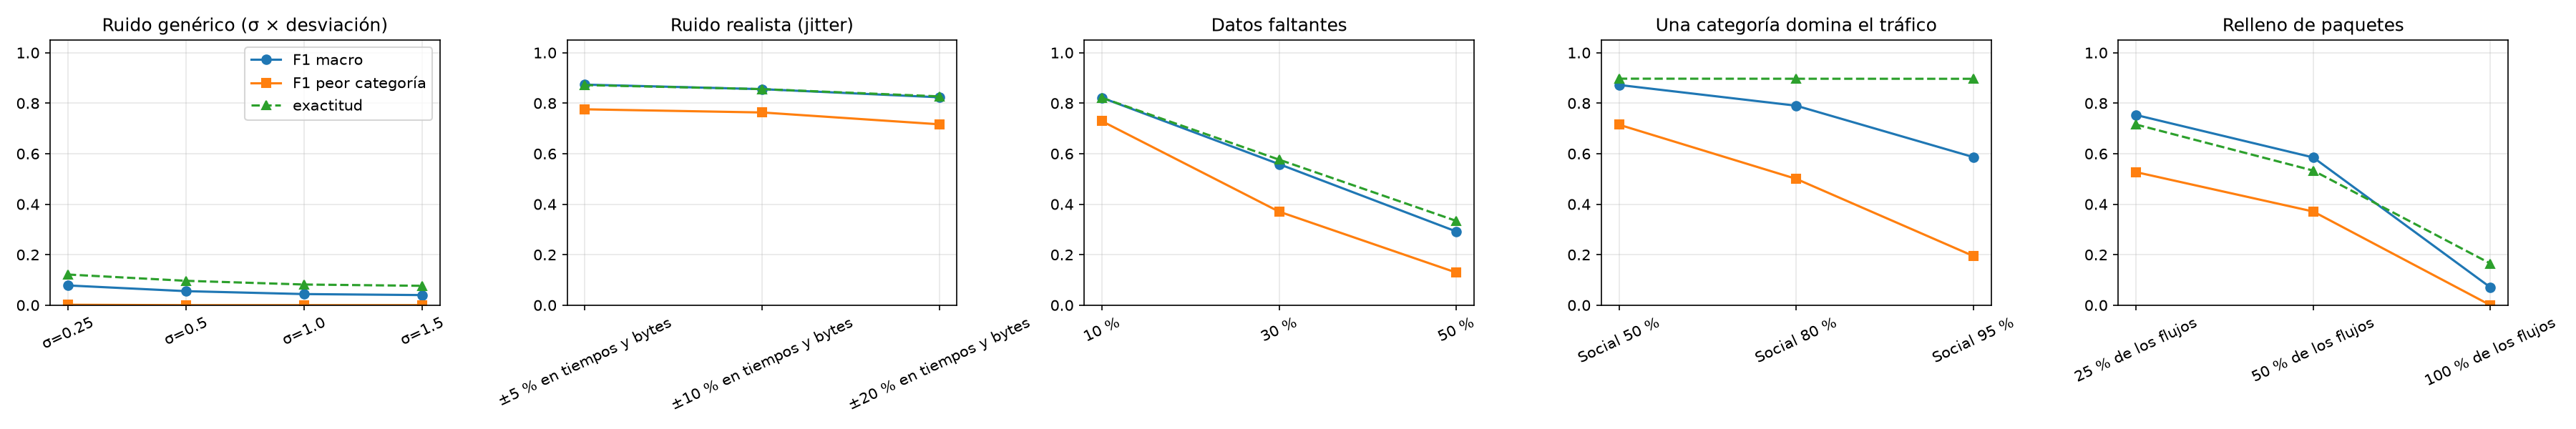

In [6]:
escenarios = pd.read_csv(RES / "semana5" / "workshop1" / "resumen_escenarios.csv")
display(escenarios[["escenario", "nivel", "f1_macro", "f1_peor_categoria", "accuracy", "caida_f1", "veredicto"]])
figura(RES / "semana5" / "workshop1" / "escenarios.png", ancho=1100)

El modelo tolera lo que suele pasar en una red: variaciones del 10 % en tiempos y bytes y dos meses de deriva. No
tolera la pérdida de datos, los cambios fuertes en la composición del tráfico, las poblaciones de flujos que no vio ni
el relleno deliberado de paquetes, que lo deja prácticamente inútil.

## 6. Deriva en el tiempo

La tabla muestra el F1 macro de cada modelo en octubre, noviembre y diciembre.

In [7]:
tabla = pd.read_csv(RES / "comparativa" / "tabla_comparativa.csv", index_col=0)
tabla[["f1_macro", "f1_macro_2022-11", "f1_macro_2022-12"]].rename(
    columns={"f1_macro": "Octubre", "f1_macro_2022-11": "Noviembre", "f1_macro_2022-12": "Diciembre"})

,Octubre,Noviembre,Diciembre
modelo,,,
random_forest,0.8602,0.8279,0.8172
xgboost,0.9032,0.8706,0.8556
cnn1d,0.8010,0.7628,0.7482
transformer,0.8332,0.7904,0.7734


Todos los modelos pierden desempeño con los meses, de forma gradual. XGBoost cae unos 4,7 puntos de octubre a
diciembre. En un despliegue real habría que vigilar esta deriva cada mes y reentrenar periódicamente.

## Conclusiones y limitaciones

1. El modelo alcanza 0,903 de F1 macro en datos nunca usados para decidir, y la configuración optimizada 0,911.
2. Su confianza es fiable, lo que permite abstenerse cuando duda.
3. Se equivoca sobre todo entre servicios que comparten infraestructura y en flujos muy cortos o muy largos.
4. Es robusto frente a las variaciones habituales de una red, pero frágil ante la pérdida de datos, los cambios fuertes
   en el tráfico y el relleno de paquetes.

**Limitaciones.** Octubre ya se había consultado antes de la semana 5, aunque las decisiones se tomaron con validación.
El tiempo de respuesta y la calibración del modelo optimizado no se midieron todavía.